# 06 – Evaluace (ROC, EER) a perceptron/MLP

**Cíl kroku:** ověřit akceptační kritéria ze zadání a porovnat klasifikátor podle nejbližšího souseda s neuronovými sítěmi.

Akceptační kritéria (testovací sada):
- EER ≤ 5 % pro každou hodnotu mince, průměr přes hodnoty ≤ 3 %,
- AUC ≥ 0,98 pro každou hodnotu,
- přesně správný součet u ≥ 90 % snímků.

**Vstup:** příznaky všech detekovaných mincí z kroku 05 (`results/05_priznaky.csv`). Rozdělení dat je stejné:
učíme na `samostatne/` + `mix/`, parametry vybíráme na `dotyk/`, `test/` vyhodnocujeme jednou, `robust/` je boční světlo.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import Perceptron
from sklearn.metrics import roc_curve
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from coins.classify import NearestNeighborScores
from coins.evaluate import eer, roc_per_class

warnings.filterwarnings("ignore", category=UserWarning)
# numpy na macOS (Accelerate) hlásí u maticového násobení falešné „divide by zero“; výsledky to neovlivňuje
warnings.filterwarnings("ignore", category=RuntimeWarning, module="sklearn")
VALUES = [1, 2, 5, 10, 20, 50]
OUT = ROOT / "results"

T = pd.read_csv(OUT / "05_priznaky.csv")
ann = pd.read_csv(ROOT / "data" / "dataset" / "anotace.csv", sep=";")
known = T[T.hodnota.notna()].copy()
known["hodnota"] = known.hodnota.astype(int)
train = known[known.sada.isin(["samostatne", "mix"])]
val = known[known.sada == "dotyk"]
test = known[known.sada == "test"]
robust = known[known.sada == "robust"]
pd.Series({"trénovací": len(train), "validační": len(val), "testovací": len(test), "robust": len(robust)}, name="mincí")

trénovací    360
validační    116
testovací    160
robust        39
Name: mincí, dtype: int64

## 1. EER a ROC

Pro hodnotu *c* bereme skóre třídy *c* jako „jak moc je to *c*“ a měníme práh:
- **FAR** (falešně přijaté) = podíl mincí jiné hodnoty se skóre nad prahem = FPR,
- **FRR** (falešně odmítnuté) = podíl mincí hodnoty *c* se skóre pod prahem = 1 − TPR.

**EER** je chybovost v bodě, kde FAR = FRR (mezi body ROC lineárně interpolujeme). Ukázka na umělých datech,
kde je výsledek známý: dvě normální rozdělení posunutá o 1σ mají EER = Φ(−0,5) = 30,85 %.

EER = 30.88% (teoreticky 30,85 %)


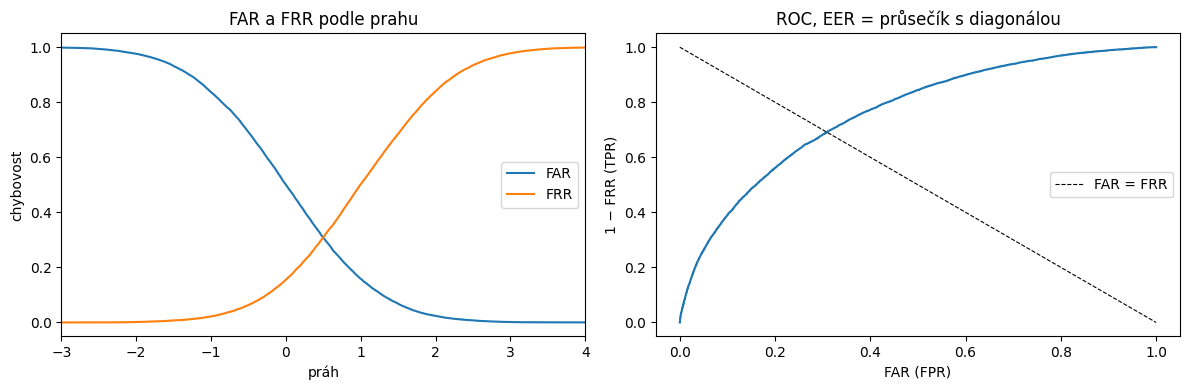

In [2]:
rng = np.random.default_rng(0)
s = np.r_[rng.normal(1, 1, 20000), rng.normal(0, 1, 20000)]
y = np.r_[np.ones(20000), np.zeros(20000)]
fpr, tpr, thr = roc_curve(y, s)
print(f"EER = {eer(fpr, tpr):.2%} (teoreticky 30,85 %)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(thr[1:], fpr[1:], label="FAR"); axes[0].plot(thr[1:], 1 - tpr[1:], label="FRR")
axes[0].set(xlim=(-3, 4), xlabel="práh", ylabel="chybovost", title="FAR a FRR podle prahu"); axes[0].legend()
axes[1].plot(fpr, tpr); axes[1].plot([0, 1], [1, 0], "k--", lw=0.8, label="FAR = FRR")
axes[1].set(xlabel="FAR (FPR)", ylabel="1 − FRR (TPR)", title="ROC, EER = průsečík s diagonálou"); axes[1].legend()
plt.tight_layout(); plt.show()

## 2. Modely a výběr parametrů na validaci

| Model | Skóre pro ROC |
|---|---|
| **kNN** (krok 05): nejbližší soused, k = 3, průměr + sytost | −vzdálenost k třídě |
| **Perceptron**: jedna vrstva, lineární hranice | `decision_function` |
| **MLP**: jedna skrytá vrstva, ReLU | pravděpodobnost třídy |

Příznaky se před perceptronem a MLP standardizují. Na validaci jsme zkoušeli 1–2 skryté vrstvy s 8–32 neurony
a regularizaci α = 10⁻⁴ až 1, vždy s 5 různými náhodnými inicializacemi. S průměrem a sytostí dosáhly všechny
varianty MLP na validaci 100 %, proto volíme **nejmenší síť: 8 neuronů, α = 0,01**.
Jako srovnání ponecháváme i **MLP nad všemi pěti příznaky** (průměr, sytost a odstín uprostřed i na okraji, síť 16–8):
kNN odstín zhoršoval, síť si ale může váhu příznaků určit sama.

In [3]:
F2 = ["prumer_mm", "S_stred"]
F5 = ["prumer_mm", "S_stred", "H_stred", "S_okraj", "H_okraj"]

def make_models():
    return {
        "kNN": (NearestNeighborScores(k=3), F2),
        "perceptron": (make_pipeline(StandardScaler(), Perceptron(max_iter=2000, random_state=0)), F2),
        "MLP": (make_pipeline(StandardScaler(), MLPClassifier((8,), alpha=1e-2, max_iter=5000, random_state=0)), F2),
        "MLP, 5 příznaků": (make_pipeline(StandardScaler(), MLPClassifier((16, 8), alpha=1e-2, max_iter=5000, random_state=0)), F5),
    }

def scores(model, X):
    return model.predict_proba(X) if hasattr(model, "predict_proba") else model.decision_function(X)

def summary(models, data):
    rows = {}
    for name, (model, feats) in models.items():
        _, table = roc_per_class(data.hodnota, scores(model, data[feats]), model.classes_)
        rows[name] = {"úspěšnost": (model.predict(data[feats]) == data.hodnota).mean(),
                      "EER průměr": table.EER.mean(), "EER max": table.EER.max(), "AUC min": table.AUC.min()}
    return pd.DataFrame(rows).T

models = make_models()
for model, feats in models.values():
    model.fit(train[feats], train.hodnota)
summary(models, val).style.format("{:.2%}", subset=["úspěšnost", "EER průměr", "EER max"]).format("{:.4f}", subset=["AUC min"])

,úspěšnost,EER průměr,EER max,AUC min
kNN,100.00%,0.17%,1.04%,0.9995
perceptron,83.62%,10.70%,21.79%,0.8134
MLP,100.00%,0.00%,0.00%,1.0000
"MLP, 5 příznaků",100.00%,0.00%,0.00%,1.0000


Perceptron je výrazně horší: hodnoty „uprostřed“ (2, 5, 10, 20 Kč) leží na ose průměru mezi ostatními a jedna přímka
je od zbytku neoddělí. Skrytá vrstva MLP to vyřeší – stejně jako kNN, který hranice nepotřebuje vůbec.

## 3. Testovací sada

Modely znovu naučíme na trénovací + validační sadě a jednou vyhodnotíme na testu.

In [4]:
dev = pd.concat([train, val])
final = make_models()
for model, feats in final.values():
    model.fit(dev[feats], dev.hodnota)

summary(final, test).style.format("{:.2%}", subset=["úspěšnost", "EER průměr", "EER max"]).format("{:.4f}", subset=["AUC min"])

,úspěšnost,EER průměr,EER max,AUC min
kNN,99.38%,2.74%,9.27%,0.9838
perceptron,93.12%,6.77%,18.25%,0.8175
MLP,97.50%,1.43%,4.11%,0.9956
"MLP, 5 příznaků",98.75%,0.11%,0.66%,0.9985


In [5]:
tables = {}
for name, (model, feats) in final.items():
    curves, tables[name] = roc_per_class(test.hodnota, scores(model, test[feats]), model.classes_)
per_class = pd.concat({n: t[["EER", "AUC"]] for n, t in tables.items()}, axis=1)
per_class.insert(0, "mincí v testu", tables["kNN"]["pozitivních"])
per_class.style.format("{:.2%}", subset=[c for c in per_class.columns if c[1:] == ("EER",)]).format(
    "{:.4f}", subset=[c for c in per_class.columns if c[1:] == ("AUC",)])

In [6]:
def criteria(table):
    return pd.Series({
        "EER ≤ 5 % pro každou třídu": table.EER.max() <= 0.05,
        "průměrné EER ≤ 3 %": table.EER.mean() <= 0.03,
        "AUC ≥ 0,98 pro každou třídu": table.AUC.min() >= 0.98,
    })

pd.DataFrame({n: criteria(t) for n, t in tables.items()})

,kNN,perceptron,MLP,"MLP, 5 příznaků"
EER ≤ 5 % pro každou třídu,False,False,True,True
průměrné EER ≤ 3 %,True,False,True,True
"AUC ≥ 0,98 pro každou třídu",True,False,True,True


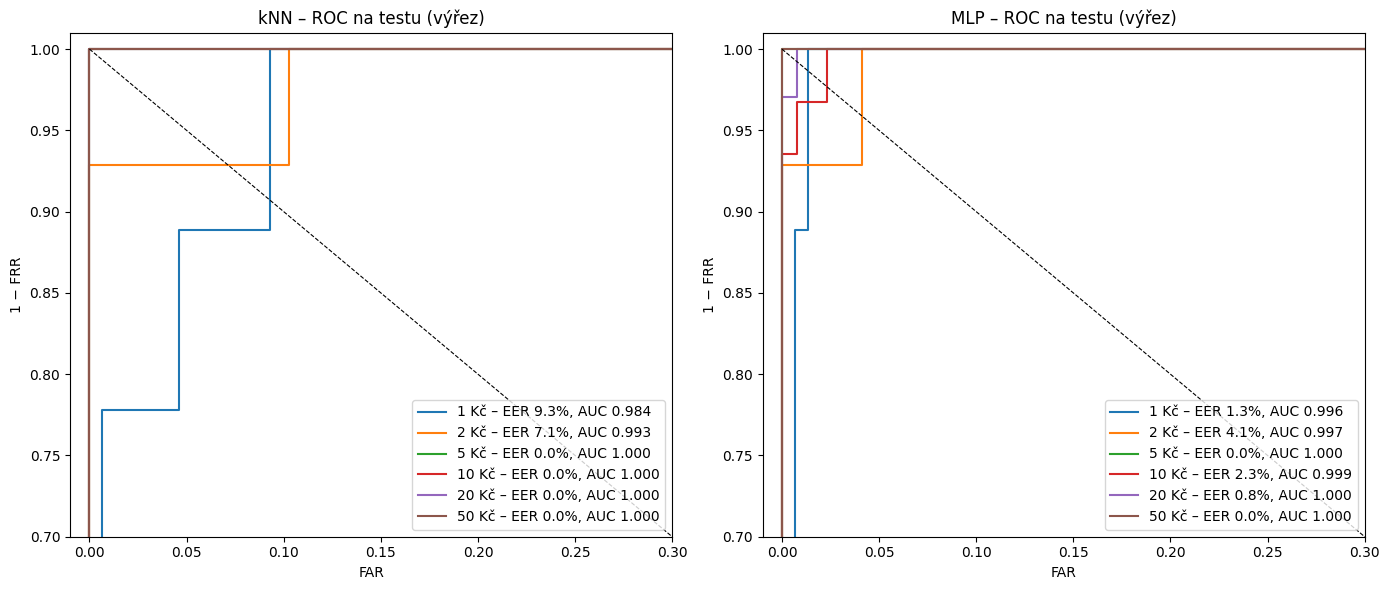

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, name in zip(axes, ["kNN", "MLP"]):
    model, feats = final[name]
    curves, table = roc_per_class(test.hodnota, scores(model, test[feats]), model.classes_)
    for c, (fpr, tpr) in curves.items():
        ax.plot(fpr, tpr, label=f"{c} Kč – EER {table.EER[c]:.1%}, AUC {table.AUC[c]:.3f}")
    ax.plot([0, 1], [1, 0], "k--", lw=0.8)
    ax.set(xlim=(-0.01, 0.3), ylim=(0.7, 1.01), xlabel="FAR", ylabel="1 − FRR", title=f"{name} – ROC na testu (výřez)")
    ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(OUT / "06_roc_test.png", dpi=120); plt.show()

**Pozor na malý počet vzorků:** v testu je jen 9 mincí 1 Kč a 14 mincí 2 Kč. Jedna chybně oskórovaná mince 1 Kč
posune FRR o 11 procentních bodů, takže EER těchto tříd je hrubé a na jedné minci hodně záleží.

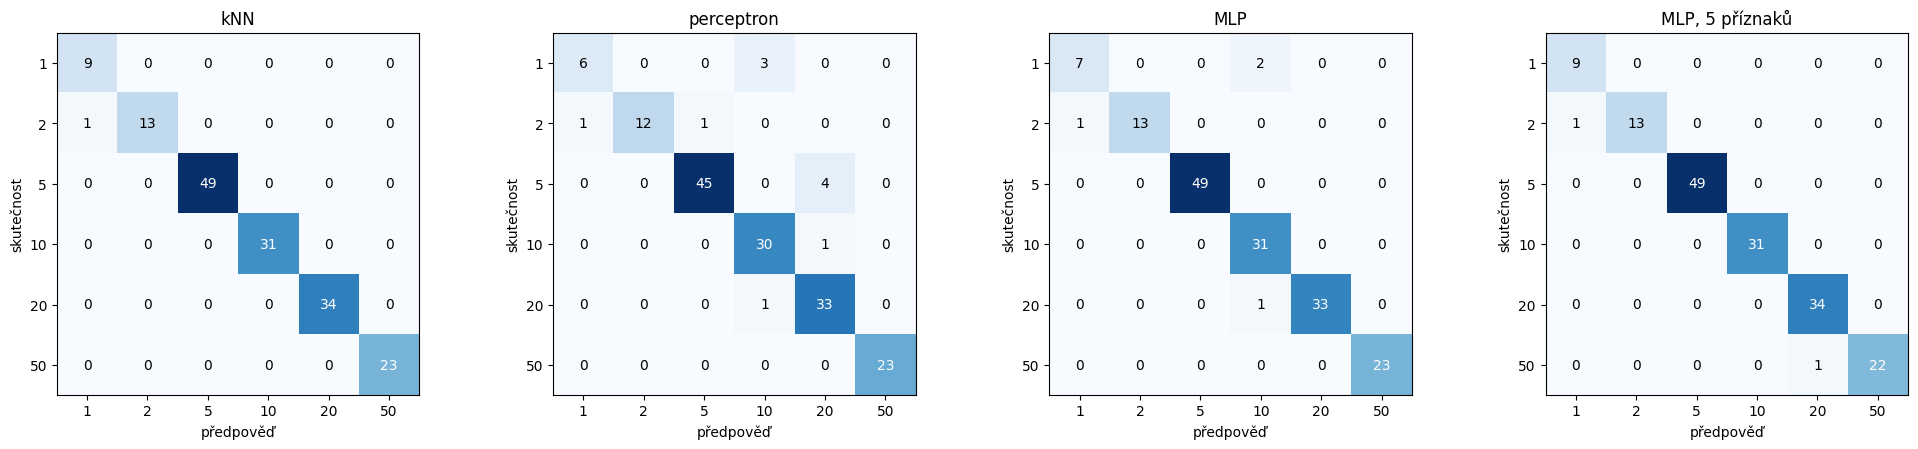

In [8]:
def confusion(y_true, y_pred):
    return pd.crosstab(pd.Series(y_true, name="skutečnost"), pd.Series(y_pred, name="předpověď")).reindex(
        index=VALUES, columns=VALUES, fill_value=0)

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (name, (model, feats)) in zip(axes, final.items()):
    cm = confusion(test.hodnota.values, model.predict(test[feats]))
    ax.imshow(cm, cmap="Blues")
    for i in range(6):
        for j in range(6):
            ax.text(j, i, cm.iat[i, j], ha="center", va="center", color="white" if cm.iat[i, j] > 20 else "black")
    ax.set(xticks=range(6), yticks=range(6), xticklabels=VALUES, yticklabels=VALUES,
           xlabel="předpověď", ylabel="skutečnost", title=name)
plt.tight_layout(); plt.savefig(OUT / "06_matice_zamen_test.png", dpi=120); plt.show()

### Rozbor chyb na testu

Na testu se nic neladí – jen se díváme, proč se výsledky liší od validace.

In [9]:
knn, _ = final["kNN"]
mlp, _ = final["MLP"]
s1 = knn.decision_function(test[F2])[:, list(knn.classes_).index(1)]
view = test[["soubor", "hodnota", "prumer_mm", "S_stred"]].assign(
    skore_kNN_1=s1, predikce_kNN=knn.predict(test[F2]), predikce_MLP=mlp.predict(test[F2]))
print("sytost 1 Kč v trénovacích datech:", dev[dev.hodnota == 1].S_stred.describe()[["mean", "std", "max"]].round(1).to_dict())
view[(view.hodnota == 1) | (view.predikce_MLP != view.hodnota) | (view.predikce_kNN != view.hodnota)].round(2)

sytost 1 Kč v trénovacích datech: {'mean': 44.8, 'std': 10.7, 'max': 58.6}


,soubor,hodnota,prumer_mm,S_stred,skore_kNN_1,predikce_kNN,predikce_MLP
479,test/test_01.jpg,1,19.91,36.72,-0.06,1,1
485,test/test_01.jpg,1,20.10,66.56,-0.28,1,1
491,test/test_02.jpg,20,25.29,118.85,-2.78,20,10
497,test/test_02.jpg,1,19.79,83.80,-0.78,1,10
507,test/test_03.jpg,1,20.21,74.69,-0.52,1,10
514,test/test_04.jpg,1,20.09,54.15,-0.03,1,1
524,test/test_05.jpg,1,20.00,53.08,-0.03,1,1
537,test/test_06.jpg,1,20.06,52.72,-0.05,1,1
549,test/test_07.jpg,1,20.17,47.34,-0.04,1,1
563,test/test_08.jpg,1,20.11,44.80,-0.06,1,1


In [10]:
stability = {seed: (make_pipeline(StandardScaler(), MLPClassifier((8,), alpha=1e-2, max_iter=5000, random_state=seed))
                    .fit(dev[F2], dev.hodnota).predict(test[F2]) == test.hodnota).sum() for seed in range(5)}
print("MLP, správně z", len(test), "podle náhodné inicializace:", stability)

MLP, správně z 160 podle náhodné inicializace: {0: np.int64(156), 1: np.int64(157), 2: np.int64(158), 3: np.int64(156), 4: np.int64(158)}


- **Tři mince 1 Kč v testu mají „růžový“ nádech** (sytost 67–84), zatímco nafocené 1 Kč v trénovacích datech mají
  sytost 45 ± 11 a nejvýš 59. Jde o jiné, zašlé kusy, než jaké byly v `samostatne/`.
- **kNN** je podle průměru zařadí správně, ale jejich skóre třídy 1 Kč je nižší než u několika mincí 2 Kč.
  Proto má 99,4 % úspěšnost, a přitom EER 1 Kč 9,3 %.
- **MLP** si v trénovacích datech „všiml“, že sytost dokonale odděluje stříbrné mince od barevných, a dvě z těchto
  mincí o průměru 20 mm označí za 10 Kč (24,5 mm). Totéž udělá s nejistou mincí 20 Kč na rozmazané `test_02`. Pravděpodobnosti přitom řadí lépe, proto lepší EER, ale horší součty.
- Záměna 2 → 1 Kč v `test_14` je chyba detekce: dvě dotýkající se mince se slily a změřený průměr nedává smysl.
- Výsledek MLP se mezi náhodnými inicializacemi liší o 1–2 mince ze 160.

## 4. Přesný součet na snímku

Kontrola celého systému: sečteme předpovězené hodnoty **všech** detekcí na snímku (i falešných) a porovnáme
s anotovaným součtem. Chybějící mince (chyba detekce) se projeví nižším součtem.

In [11]:
def sum_accuracy(model, feats, sada):
    det = T[T.sada == sada]
    pred = pd.Series(model.predict(det[feats]), index=det.index).groupby(det.soubor).sum()
    truth = ann[ann.sada == sada].set_index("soubor").soucet
    return (pred.reindex(truth.index, fill_value=0) == truth).mean()

pd.DataFrame({name: {"test": sum_accuracy(m, f, "test"), "robust": sum_accuracy(m, f, "robust")}
              for name, (m, f) in final.items()}).T.style.format("{:.1%}")

,test,robust
kNN,93.8%,16.7%
perceptron,50.0%,0.0%
MLP,81.2%,0.0%
"MLP, 5 příznaků",87.5%,0.0%


## 5. Robustnost: boční světlo

Na `robust/` se nic neladilo. Ukazuje, jak se metody chovají mimo podmínky, pro které byly naučené.

In [12]:
summary(final, robust).style.format("{:.2%}", subset=["úspěšnost", "EER průměr", "EER max"]).format("{:.4f}", subset=["AUC min"])

,úspěšnost,EER průměr,EER max,AUC min
kNN,74.36%,23.18%,48.57%,0.6857
perceptron,48.72%,24.13%,50.00%,0.5500
MLP,58.97%,19.12%,50.00%,0.6857
"MLP, 5 příznaků",58.97%,23.24%,50.00%,0.6429


In [13]:
rob = pd.concat({n: roc_per_class(robust.hodnota, scores(m, robust[f]), m.classes_)[1][["EER", "AUC"]]
                 for n, (m, f) in final.items()}, axis=1)
rob.style.format("{:.2f}")

## 6. Uložení

In [14]:
pd.concat({"test": per_class.iloc[:, 1:], "robust": rob}, names=["sada"]).round(4).to_csv(OUT / "06_eer_auc.csv")
summary(final, test).round(4).to_csv(OUT / "06_souhrn_test.csv")

## Závěr

| | kNN | perceptron | MLP | MLP, 5 příznaků |
|---|---|---|---|---|
| úspěšnost po mincích | **99,4 %** | 93,1 % | 97,5 % | 98,8 % |
| EER průměr / max | 2,7 % / 9,3 % | 6,8 % / 18,3 % | **1,4 % / 4,1 %** | **0,1 % / 0,7 %** |
| AUC min | 0,984 | 0,818 | 0,996 | **0,999** |
| přesný součet (test) | **93,8 %** | 50,0 % | 81,2 % | 87,5 % |

- **Žádný model nesplní všechna kritéria najednou.** kNN má nejlepší součty (93,8 % ≥ 90 %) a průměrné EER 2,7 % ≤ 3 %,
  ale EER 1 Kč (9,3 %) a 2 Kč (7,1 %) přesahuje 5 %. MLP splní kritéria EER i AUC, ale součet je správně jen na 81–88 % snímků.
- Příčinou je hlavně **posun dat**: v testu jsou zašlé „růžové“ mince 1 Kč, jaké trénovací data neobsahují.
  Validace (`dotyk/`) byla pro výběr modelu nasycená (100 % u všech kromě perceptronu), takže tento rozdíl neodhalila.
- **Perceptron** (lineární hranice) na úlohu nestačí – hodnoty uprostřed osy průměru nejdou oddělit jednou přímkou.
- **Malý počet vzorků:** 9 mincí 1 Kč a 14 mincí 2 Kč v testu, jedna mince = 7–11 procentních bodů EER.
- **Boční světlo:** všechny modely selhávají (AUC 0,55–0,69); barva i okraj masky se mění se světlem.

**Doporučení:** dofotit více různých kusů 1 a 2 Kč (zašlé, nové, obě strany) a validační sadu udělat z jiných kusů mincí
než trénovací, aby validace zachytila posun barvy. Barvu měřit relativně k podložce, nebo ji u stříbrných mincí
nahradit poměrem jasu, aby tolik nezávisela na světle. Srovnání s CNN v kroku 08.